<a href="https://colab.research.google.com/github/SelinBeyaz01/BUS392-Steam-Project/blob/selin-analysis/BUS392_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install kagglehub

In [3]:
import kagglehub
path = kagglehub.dataset_download("hubertsidorowicz/steam-games-dataset-daily-updates")

100%|██████████| 200M/200M [00:02<00:00, 99.9MB/s]

Extracting files...


In [4]:
import pandas as pd
gamesData_location = path + "/steam_games.csv"
gamesData = pd.read_csv(gamesData_location)
gamesData.head()

/tmp/ipykernel_447/1104197516.py:3: DtypeWarning: Columns (30,31,32) have mixed types. Specify dtype option on import or set low_memory=False.
  gamesData = pd.read_csv(gamesData_location)


,app_id,name,release_date,price,price_status,estimated_owners,developers,publishers,genres,categories,...,linux,header_image,screenshots,movies,website,support_url,support_email,metacritic_url,steam_store_available,steam_spy_available
0,2527550,Roll The Bones,2026-07-28,9.99,paid,"0 .. 20,000","[""Shrimp Industries""]","[""Proteus Interactive""]","[{""id"": ""1"", ""description"": ""Action""}, {""id"": ...","[{""id"": 2, ""description"": ""Single-player""}, {""...",...,False,https://shared.akamai.steamstatic.com/store_it...,"[{""id"": 0, ""path_thumbnail"": ""https://shared.a...","[{""id"": 257368384, ""name"": ""Early Access Trail...",https://shrimp.industries,NaN,support@shrimp.industries,NaN,True,True
1,2806050,Halo: Campaign Evolved,2026-07-28,49.99,paid,"0 .. 20,000","[""Halo Studios""]","[""Xbox Game Studios""]","[{""id"": ""1"", ""description"": ""Action""}, {""id"": ...","[{""id"": 2, ""description"": ""Single-player""}, {""...",...,False,https://shared.akamai.steamstatic.com/store_it...,"[{""id"": 0, ""path_thumbnail"": ""https://shared.a...","[{""id"": 257384268, ""name"": ""Play Now"", ""thumbn...",https://www.halowaypoint.com/,https://aka.ms/halosupport,NaN,NaN,True,True
2,2789980,Sinned Arena,2026-07-28,8.99,paid,"0 .. 20,000","[""xDenny""]","[""xDenny""]","[{""id"": ""1"", ""description"": ""Action""}, {""id"": ...","[{""id"": 2, ""description"": ""Single-player""}, {""...",...,False,https://shared.akamai.steamstatic.com/store_it...,"[{""id"": 0, ""path_thumbnail"": ""https://shared.a...","[{""id"": 257381974, ""name"": ""Trailer 3"", ""thumb...",https://x.com/xdenny_dev,NaN,xdenny.dev@gmail.com,NaN,True,True
3,3041730,Go North,2026-07-28,14.99,paid,"0 .. 20,000","[""gazuntype""]","[""gazuntype""]","[{""id"": ""25"", ""description"": ""Adventure""}, {""i...","[{""id"": 2, ""description"": ""Single-player""}, {""...",...,False,https://shared.akamai.steamstatic.com/store_it...,"[{""id"": 0, ""path_thumbnail"": ""https://shared.a...","[{""id"": 257385987, ""name"": ""Go North - Launch""...",NaN,NaN,tade@gazuntype.com,NaN,True,True
4,3044420,Rabbit Comes Home,2026-07-28,6.99,paid,"0 .. 20,000","[""ZIPSTED""]","[""ZIPSTED""]","[{""id"": ""1"", ""description"": ""Action""}, {""id"": ...","[{""id"": 2, ""description"": ""Single-player""}, {""...",...,True,https://shared.akamai.steamstatic.com/store_it...,"[{""id"": 0, ""path_thumbnail"": ""https://shared.a...","[{""id"": 257216505, ""name"": ""Rabbit Comes Home....",NaN,NaN,support@zipsted.com,NaN,True,True


In [5]:
#Clean the data
import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt
import seaborn as sns

# Reload the data without the mixed-type warning
gamesData = pd.read_csv(gamesData_location, low_memory=False)

# Keep the columns we need
columns_needed = [
    'app_id', 'name', 'release_date', 'price', 'price_status',
    'estimated_owners', 'genres', 'categories',
    'positive', 'negative', 'recommendations',
    'average_playtime_forever'
]

games = gamesData[columns_needed].copy()

# Fix dates and make numerical columns numeric
games['release_date'] = pd.to_datetime(games['release_date'], errors='coerce')
games['release_year'] = games['release_date'].dt.year

number_columns = [
    'price', 'positive', 'negative',
    'recommendations', 'average_playtime_forever'
]

for column in number_columns:
    games[column] = pd.to_numeric(games[column], errors='coerce')

# Remove games missing essential information
games = games.dropna(subset=['app_id', 'name', 'release_date'])

print("Number of games after cleaning:", len(games))
games.head()

Number of games after cleaning: 148891


,app_id,name,release_date,price,price_status,estimated_owners,genres,categories,positive,negative,recommendations,average_playtime_forever,release_year
0,2527550,Roll The Bones,2026-07-28,9.99,paid,"0 .. 20,000","[{""id"": ""1"", ""description"": ""Action""}, {""id"": ...","[{""id"": 2, ""description"": ""Single-player""}, {""...",0.0,0.0,NaN,0.0,2026.0
1,2806050,Halo: Campaign Evolved,2026-07-28,49.99,paid,"0 .. 20,000","[{""id"": ""1"", ""description"": ""Action""}, {""id"": ...","[{""id"": 2, ""description"": ""Single-player""}, {""...",0.0,0.0,4936.0,0.0,2026.0
2,2789980,Sinned Arena,2026-07-28,8.99,paid,"0 .. 20,000","[{""id"": ""1"", ""description"": ""Action""}, {""id"": ...","[{""id"": 2, ""description"": ""Single-player""}, {""...",0.0,0.0,NaN,0.0,2026.0
3,3041730,Go North,2026-07-28,14.99,paid,"0 .. 20,000","[{""id"": ""25"", ""description"": ""Adventure""}, {""i...","[{""id"": 2, ""description"": ""Single-player""}, {""...",0.0,0.0,NaN,0.0,2026.0
4,3044420,Rabbit Comes Home,2026-07-28,6.99,paid,"0 .. 20,000","[{""id"": ""1"", ""description"": ""Action""}, {""id"": ...","[{""id"": 2, ""description"": ""Single-player""}, {""...",0.0,0.0,NaN,0.0,2026.0


In [8]:
#Create popularity measures
# Convert ownership ranges, such as "0 - 20,000," into estimated midpoints
def owner_midpoint(owner_range):
    try:
        clean_range = str(owner_range).replace(',', '')
        low, high = clean_range.split(' - ')
        return (int(low) + int(high)) / 2
    except:
        return np.nan

games['estimated_owners_num'] = games['estimated_owners'].apply(owner_midpoint)

# Create total reviews and positive-review rate
games['total_reviews'] = games['positive'].fillna(0) + games['negative'].fillna(0)

games['positive_review_rate'] = np.where(
    games['total_reviews'] > 0,
    games['positive'] / games['total_reviews'],
    np.nan
)

# Required if / elif / else statement
def popularity_level(row):
    if row['recommendations'] >= 100000:
        return 'High'
    elif row['recommendations'] >= 10000:
        return 'Medium'
    else:
        return 'Low'

games['popularity_level'] = games.apply(popularity_level, axis=1)

games[['name', 'estimated_owners_num', 'recommendations',
       'total_reviews', 'average_playtime_forever',
       'popularity_level']].head()

,name,estimated_owners_num,recommendations,total_reviews,average_playtime_forever,popularity_level
0,Roll The Bones,NaN,NaN,0.0,0.0,Low
1,Halo: Campaign Evolved,NaN,4936.0,0.0,0.0,Low
2,Sinned Arena,NaN,NaN,0.0,0.0,Low
3,Go North,NaN,NaN,0.0,0.0,Low
4,Rabbit Comes Home,NaN,NaN,0.0,0.0,Low


In [9]:
#Popularity question: top games and free versus paid
top_recommended = games.sort_values(
    by='recommendations',
    ascending=False
)[[
    'name', 'price_status', 'estimated_owners_num',
    'recommendations', 'total_reviews',
    'average_playtime_forever'
]].head(10)

top_recommended

,name,price_status,estimated_owners_num,recommendations,total_reviews,average_playtime_forever
17322,Counter-Strike 2,free,NaN,5179195.0,8815087.0,0.0
4705,Grand Theft Auto V Legacy,unavailable,NaN,1888724.0,1990556.0,0.0
64253,PUBG: BATTLEGROUNDS,free,NaN,1762310.0,2557944.0,0.0
68190,Tom Clancy's Rainbow Six Siege,free,NaN,1248271.0,376548.0,0.0
68222,Tom Clancy's Rainbow Six Siege,free,NaN,1248271.0,377017.0,0.0
68191,Tom Clancy's Rainbow Six Siege,free,NaN,1248271.0,376907.0,0.0
68221,Tom Clancy's Rainbow Six Siege,free,NaN,1248266.0,376369.0,0.0
650,Tom Clancy's Rainbow Six Siege,free,NaN,1247987.0,1398584.0,0.0
5650,Terraria,paid,NaN,1227375.0,1409473.0,0.0
3555,Rust,paid,NaN,1155024.0,1227784.0,0.0


In [16]:
price_comparison = price_games.groupby('price_status').agg(
    games_count=('app_id', 'count'),
    average_owners=('estimated_owners_num', 'mean'),
    average_recommendations=('recommendations', 'mean'),
    average_total_reviews=('total_reviews', 'mean'),
    average_playtime=('average_playtime_forever', 'mean')
).round(2)

price_comparison

,games_count,average_owners,average_recommendations,average_total_reviews,average_playtime
price_status,,,,,
free,28527,22236.32,727.92,1197.65,25.65
paid,119012,35091.95,1355.37,913.17,65.40


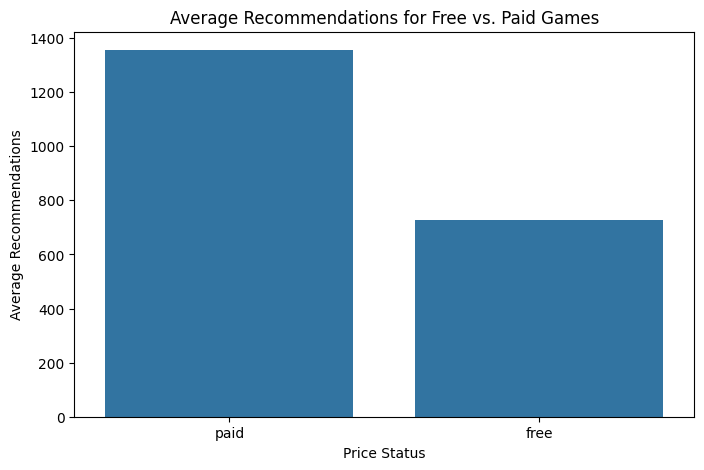

In [17]:
price_games = games[games['price_status'].isin(['free', 'paid'])]

plt.figure(figsize=(8, 5))

sns.barplot(
    data=price_games,
    x='price_status',
    y='recommendations',
    estimator='mean',
    errorbar=None
)

plt.title('Average Recommendations for Free vs. Paid Games')
plt.xlabel('Price Status')
plt.ylabel('Average Recommendations')
plt.show()

In [18]:
# Genre Analysis
# Extract genre names from the genre lists in the dataset
def extract_descriptions(value):
    try:
        items = json.loads(value)
        return [item['description'] for item in items]
    except:
        return []

games['genre_list'] = games['genres'].apply(extract_descriptions)

# Required list and for-loop usage
all_genres = []

for genre_group in games['genre_list']:
    for genre in genre_group:
        all_genres.append(genre)

genre_counts = pd.Series(all_genres).value_counts()

print("Most common genres:")
print(genre_counts.head(10))

Most common genres:
Indie           37634
Casual          21477
Action          20997
Adventure       18371
Simulation      11568
Strategy        11424
RPG              8785
Early Access     5384
Free To Play     4328
Sports           2295
Name: count, dtype: int64


In [19]:
# Assign each game to every genre it belongs to
genre_games = games.explode('genre_list').dropna(subset=['genre_list'])

genre_summary = genre_games.groupby('genre_list').agg(
    number_of_games=('app_id', 'count'),
    average_recommendations=('recommendations', 'mean'),
    average_playtime=('average_playtime_forever', 'mean'),
    average_positive_rate=('positive_review_rate', 'mean')
).round(2).sort_values('number_of_games', ascending=False)

genre_summary.head(10)

,number_of_games,average_recommendations,average_playtime,average_positive_rate
genre_list,,,,
Indie,37634,4812.41,0.99,0.72
Casual,21477,3022.53,1.04,0.72
Action,20997,12366.10,0.54,0.71
Adventure,18371,7673.26,0.83,0.72
Simulation,11568,6627.49,2.31,0.68
Strategy,11424,5271.19,2.13,0.70
RPG,8785,8539.33,3.05,0.71
Early Access,5384,6022.07,0.66,0.65
Free To Play,4328,50962.25,0.52,0.74


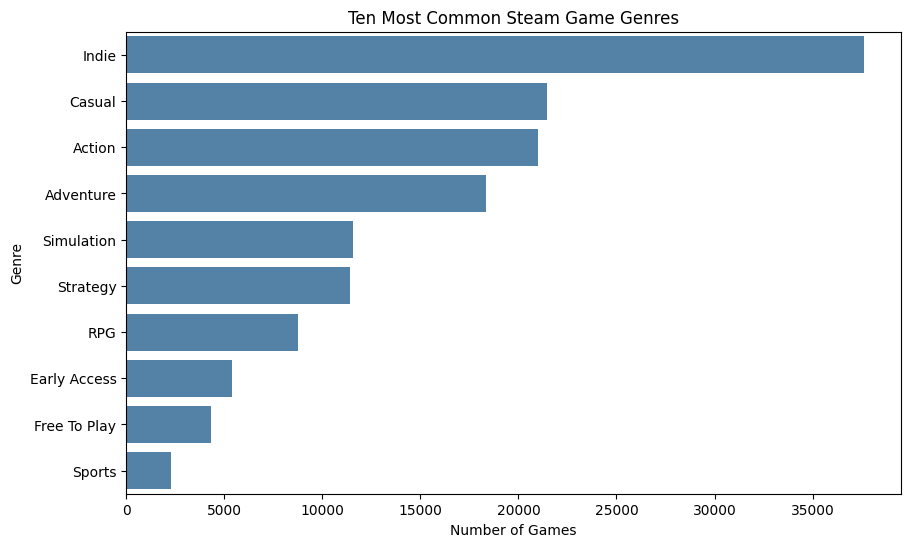

In [20]:
top_10_genres = genre_summary.head(10).reset_index()

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_10_genres,
    y='genre_list',
    x='number_of_games',
    color='steelblue'
)

plt.title('Ten Most Common Steam Game Genres')
plt.xlabel('Number of Games')
plt.ylabel('Genre')
plt.show()